# Step 3. Feature Engineering
## Moneyball 2.0 — игровые, результативные и экономические признаки

**Вход:** очищенная таблица Step 2 — мужчины-CM на **26.09.2022**, 2 886 игроков с годной исторической оценкой. Здесь не расширяем её до всех 4 184 CM Step 1: охват матриц явно ограничен очищенной выборкой Step 2.

**Выход:** три смысловые группы признаков, Goals/90 и Assists/90, стандартизированные игровые матрицы, матрица оценки стоимости и manifest ролей колонок. Обучения предсказательной модели или оценки её качества здесь нет.

Рыночная стоимость, возраст, потенциал и результативность **не входят в вектор игрового сходства**. Все обучаемые преобразования fit только на тренировочных игроках; test используется только для transform.

| Группа | Состав | Роль |
| --- | --- | --- |
| Technical / playing | 18 детальных характеристик FIFA, включая физику и оборону | Основной вектор сходства |
| Performance | Голы, ассисты, минуты, Goals/90, Assists/90 сезона 21/22 | Дополнительный исследовательский слой с пропусками и флагами |
| Economic | Историческая оценка TM, возраст на cutoff, FIFA potential и potential gap | Контекст экономической оценки; цена — цель/бюджет, не вход сходства |

Сохраняем основной [контракт v1](../config/feature_set_v1.json): 18 входов сходства и 27 исходных входов модели цены. Potential добавляется в экономический анализ как субъективная игровая оценка; в обязательный X_value v1 он не добавляется без отдельного сравнения моделей.


In [1]:
from pathlib import Path
import hashlib
import json
import os
import sys
import zipfile
import numpy as np
import pandas as pd
import sklearn
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
from sklearn.model_selection import GroupShuffleSplit
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
%matplotlib inline

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "config/feature_set_v1.json").exists())
sys.path.insert(0, str(ROOT / "scripts"))
from profile_moneyball_data import ARCHIVES
CONTRACT = json.loads((ROOT / "config/feature_set_v1.json").read_text(encoding="utf-8"))
INPUT = ROOT / "data/processed/preprocessing"
OUT = ROOT / "data/processed/features"
OUT.mkdir(parents=True, exist_ok=True)
CUTOFF = CONTRACT["primary_snapshot"]["fifa_update_date"]
PERFORMANCE_SEASON = "21/22"
ASSUMED_SEASON_END = "2022-06-30"
MIN_RELIABLE_MINUTES = 450
SEED = 42
CORE = CONTRACT["similarity_features"]
VALUE_FEATURES = CORE + CONTRACT["valuation_additional_numeric_features"] + CONTRACT["valuation_additional_categorical_features"]
plt.rcParams.update({"font.family": "DejaVu Sans", "figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
pd.set_option("display.max_columns", 35)
figures = []

def digest(path):
    h = hashlib.sha256()
    with Path(path).open("rb") as f:
        for block in iter(lambda: f.read(8 * 1024 * 1024), b""):
            h.update(block)
    return h.hexdigest()

def show(fig, name):
    fig.savefig(OUT / f"{name}.png", dpi=135, bbox_inches="tight")
    figures.append(name)
    plt.show()
    plt.close(fig)

input_manifest = json.loads((INPUT / "dataset_manifest.json").read_text(encoding="utf-8"))
input_path = INPUT / input_manifest["dataset"]
assert digest(input_path) == input_manifest["sha256"]
players = pd.read_csv(input_path, dtype={"fifa_id": str, "tm_id": str, "league_id": str})
assert len(players) == input_manifest["rows"] and players.fifa_id.is_unique and players.tm_id.is_unique
assert players.as_of_date.eq(CUTOFF).all() and players.fifa_update_date.eq(CUTOFF).all()
assert players.market_value_date.le(CUTOFF).all()
assert players[CORE].notna().all().all()
print("Input shape:", players.shape, "; cutoff:", CUTOFF, "; scikit-learn:", sklearn.__version__)


Input shape: (2886, 47) ; cutoff: 2022-09-26 ; scikit-learn: 1.7.2


### 1. Источники дополнительных признаков

Потенциал читается из того же FIFA-среза, что и игровые характеристики: FIFA 23, 26.09.2022. Статистика выступлений читается потоково из исходного ZIP TM и ограничивается **только сезоном 21/22**. Записи текущего 22/23 и более поздних сезонов исключаются до агрегации.

Для сезона 21/22 используем предположение об окончании 30.06.2022. Архив не содержит даты первой публикации сезонных итогов и истории исправлений. Поэтому performance — ретроспективный дополнительный анализ, **не доказанно point-in-time вход основного v1**. Календарные сезоны 2021/2022 не смешиваем с 21/22 без проверенной карты календарей соревнований.


In [2]:
folders = ([Path(os.environ["MONEYBALL_DATA_DIR"])] if os.environ.get("MONEYBALL_DATA_DIR") else [])
folders += [ROOT / "data/raw", Path.home() / "Downloads"]
sources = {}
source_hashes = {}
for name in ["fifa_male", "transfermarkt"]:
    path = next((folder / ARCHIVES[name] for folder in folders if (folder / ARCHIVES[name]).exists()), None)
    if path is None:
        raise FileNotFoundError(f"Нет {ARCHIVES[name]}; укажите MONEYBALL_DATA_DIR.")
    reference = json.loads((ROOT / f"reports/data_profiling/{name}_archive.json").read_text(encoding="utf-8"))
    source_hashes[name] = digest(path)
    assert source_hashes[name] == reference["sha256"]
    sources[name] = path

with zipfile.ZipFile(sources["fifa_male"]) as z:
    potential_source = pd.read_csv(z.open("male_players (legacy).csv"), dtype=str, na_filter=False,
                                   usecols=["player_id", "fifa_version", "fifa_update_date", "potential", "overall"])
potential_source = potential_source.loc[potential_source.fifa_version.eq("23") & potential_source.fifa_update_date.eq(CUTOFF)]
assert potential_source.player_id.is_unique
potential_source = potential_source.rename(columns={"player_id": "fifa_id", "fifa_update_date": "potential_source_date"})
potential_source["potential"] = pd.to_numeric(potential_source.potential, errors="coerce")
potential_source["source_overall"] = pd.to_numeric(potential_source.overall, errors="coerce")
enriched = players.merge(potential_source[["fifa_id", "potential", "potential_source_date", "source_overall"]],
                          on="fifa_id", how="left", validate="one_to_one")
assert len(enriched) == len(players)
assert enriched.potential_source_date.eq(CUTOFF).all()
assert enriched.source_overall.eq(enriched.overall).all()
enriched["potential_gap"] = enriched.potential - enriched.overall
assert enriched.potential.between(1, 99).all() and enriched.potential_gap.ge(0).all()
enriched = enriched.drop(columns="source_overall")

perf_columns = ["player_id", "season_name", "competition_id", "team_id", "goals", "assists", "minutes_played"]
parts, season_counts = [], {}
with zipfile.ZipFile(sources["transfermarkt"]) as z:
    for chunk in pd.read_csv(z.open("player_performances/player_performances.csv"), dtype=str, na_filter=False,
                             usecols=perf_columns, chunksize=100_000):
        for season, n in chunk.season_name.value_counts().items():
            season_counts[season] = season_counts.get(season, 0) + int(n)
        parts.append(chunk.loc[chunk.season_name.eq(PERFORMANCE_SEASON)].copy())
perf = pd.concat(parts, ignore_index=True)
del parts
assert perf.season_name.eq(PERFORMANCE_SEASON).all()
assert pd.Timestamp(ASSUMED_SEASON_END) < pd.Timestamp(CUTOFF)
print("Исходных записей 21/22:", len(perf), "; исключено других сезонов:", sum(season_counts.values()) - len(perf))


Исходных записей 21/22: 104402 ; исключено других сезонов: 1774317


### 2. Performance Features: строгая агрегация и формулы

$$GoalsPer90 = \frac{Goals}{MinutesPlayed}\times90$$
$$AssistsPer90 = \frac{Assists}{MinutesPlayed}\times90$$

**Goals включает пенальти**, как в предложенной формуле. Это отличается от экспериментального `prev_goals_p90` Step 1, где использовались непенальтийные голы; тот столбец здесь не переиспользуется.

Сначала удаляются точные дубли на уровне игрок–сезон–соревнование–команда. Разные записи на одном ключе помещаются в карантин; для затронутого игрока сезонный итог не вычисляется. Минуты, голы и ассисты суммируются по всем записям сезона: пропуск/негодное значение хотя бы одной составляющей делает соответствующую сумму неизвестной.

Нулевые/отрицательные/неизвестные минуты дают missing per-90. Отдельный флаг надёжности требует **≥450 минут**; низкий объём не превращается в нулевую результативность. Порог — допущение для устойчивости, не статистически найденный оптимум.


Точных дублей: 0 ; конфликтующих строк: 0


,feature,available,coverage_pct
0,minutes_21_22,231,8.00
1,goals_per90,231,8.00
2,assists_per90,231,8.00
3,goals_per90_450,186,6.44
4,assists_per90_450,186,6.44


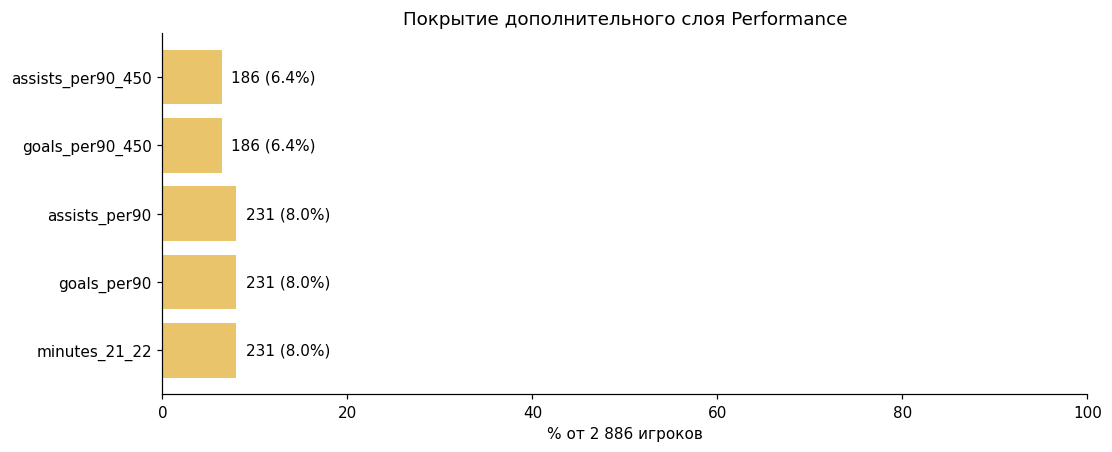

In [3]:
keys = ["player_id", "season_name", "competition_id", "team_id"]
exact_duplicates = int(perf.duplicated().sum())
perf = perf.drop_duplicates().copy()
conflicting = perf.duplicated(keys, keep=False)
conflict_rows = perf.loc[conflicting].copy()
blocked_players = set(conflict_rows.player_id)
perf = perf.loc[~perf.player_id.isin(blocked_players)].copy()
assert perf[keys].ne("").all().all()
assert not perf.duplicated(keys).any()
for column in ["goals", "assists", "minutes_played"]:
    values = pd.to_numeric(perf[column], errors="coerce")
    invalid = ~np.isfinite(values) | values.lt(0)
    if column in ["goals", "assists"]:
        invalid |= values.mod(1).ne(0) & values.notna()
    perf[column] = values.mask(invalid)

def complete_sum(series):
    return series.sum(min_count=len(series))

season = perf.groupby("player_id").agg(
    goals_21_22=("goals", complete_sum), assists_21_22=("assists", complete_sum),
    minutes_21_22=("minutes_played", complete_sum), performance_records=("season_name", "size")
).reset_index().rename(columns={"player_id": "tm_id"})

def per90(numerator, minutes):
    n = pd.to_numeric(numerator, errors="coerce").astype(float)
    m = pd.to_numeric(minutes, errors="coerce").astype(float)
    valid = np.isfinite(n) & np.isfinite(m) & n.ge(0) & m.gt(0)
    return (90 * n / m.where(valid)).where(valid)

season["goals_per90"] = per90(season.goals_21_22, season.minutes_21_22)
season["assists_per90"] = per90(season.assists_21_22, season.minutes_21_22)
season["performance_season"] = PERFORMANCE_SEASON
season["assumed_season_end"] = ASSUMED_SEASON_END
enriched = enriched.merge(season, on="tm_id", how="left", validate="one_to_one")
assert len(enriched) == len(players)
enriched["has_performance_record"] = enriched.performance_records.notna()
enriched["minutes_known"] = enriched.minutes_21_22.notna()
enriched["goals_per90_reliable"] = enriched.goals_per90.notna() & enriched.minutes_21_22.ge(MIN_RELIABLE_MINUTES)
enriched["assists_per90_reliable"] = enriched.assists_per90.notna() & enriched.minutes_21_22.ge(MIN_RELIABLE_MINUTES)
# Separate optional model inputs keep unreliable rates missing, never zero-filled.
enriched["goals_per90_450"] = enriched.goals_per90.where(enriched.goals_per90_reliable)
enriched["assists_per90_450"] = enriched.assists_per90.where(enriched.assists_per90_reliable)
coverage = pd.DataFrame([
    {"feature": f, "available": int(enriched[f].notna().sum()), "coverage_pct": 100 * enriched[f].notna().mean()}
    for f in ["minutes_21_22", "goals_per90", "assists_per90", "goals_per90_450", "assists_per90_450"]])
display(coverage.round(2))
print("Точных дублей:", exact_duplicates, "; конфликтующих строк:", len(conflict_rows))
fig, ax = plt.subplots(figsize=(10, 4), layout="constrained")
ax.barh(coverage.feature, coverage.coverage_pct, color="#e9c46a")
ax.set(xlim=(0, 100), xlabel="% от 2 886 игроков", title="Покрытие дополнительного слоя Performance")
for i, row in coverage.iterrows():
    ax.text(row.coverage_pct + 1, i, f"{int(row.available)} ({row.coverage_pct:.1f}%)", va="center")
show(fig, "01_performance_coverage")


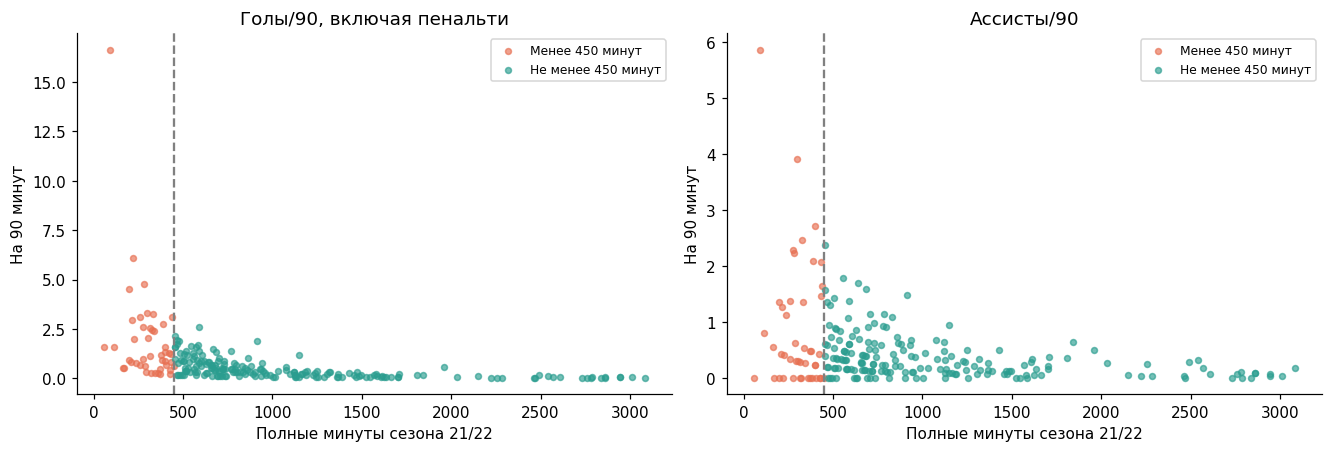

,short_name,minutes_21_22,goals_21_22,assists_21_22,goals_per90,assists_per90
3,B. Džemaili,1700.0,1.0,4.0,0.052941,0.211765
38,J. Troisi,1389.0,1.0,2.0,0.064795,0.129590
53,P. Ebert,847.0,2.0,2.0,0.212515,0.212515
71,É. Banega,862.0,10.0,6.0,1.044084,0.626450
77,J. O'Shea,780.0,3.0,8.0,0.346154,0.923077
89,M. Tekdemir,678.0,3.0,1.0,0.398230,0.132743
117,M. James,2784.0,1.0,3.0,0.032328,0.096983
137,Rochina,739.0,1.0,3.0,0.121786,0.365359
161,F. Coquelin,875.0,3.0,2.0,0.308571,0.205714
176,Edu Bedia,1359.0,1.0,1.0,0.066225,0.066225


In [4]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4), layout="constrained")
for ax, rate, reliable, title in [(axes[0], "goals_per90", "goals_per90_reliable", "Голы/90, включая пенальти"),
                                  (axes[1], "assists_per90", "assists_per90_reliable", "Ассисты/90")]:
    known = enriched[rate].notna()
    for flag, color, label in [(False, "#e76f51", "Менее 450 минут"), (True, "#2a9d8f", "Не менее 450 минут")]:
        mask = known & enriched[reliable].eq(flag)
        ax.scatter(enriched.loc[mask, "minutes_21_22"], enriched.loc[mask, rate], s=15, alpha=.65, color=color, label=label)
    ax.axvline(MIN_RELIABLE_MINUTES, color="grey", linestyle="--")
    ax.set(title=title, xlabel="Полные минуты сезона 21/22", ylabel="На 90 минут")
    ax.legend(fontsize=8)
show(fig, "02_rates_and_sample_size")
display(enriched.loc[enriched.goals_per90_reliable, ["short_name", "minutes_21_22", "goals_21_22", "assists_21_22", "goals_per90", "assists_per90"]].head(10))


### 3. Economic Features: отдельный контекст

Оценка TM уже ограничена датой cutoff и давностью ≤365 дней в Step 2. Возраст вычислен на ту же дату, potential получен из того же FIFA-среза. Производный `potential_gap = potential - overall` отражает игровую оценку запаса развития, а не гарантированный реальный рост.

Стоимость — цель оценки/бюджетный фильтр; возраст и potential — экономический контекст. Дешевизна или высокий potential сами по себе не доказывают недооценённость. Здесь не создаётся произвольный «инвестиционный рейтинг».


,count,mean,std,min,25%,50%,75%,max
tm_market_value,2886.0,3373544.70,8192345.29,25000.00,350000.00,800000.00,2500000.00,90000000.00
target_log1p_tm_value,2886.0,13.76,1.50,10.13,12.77,13.59,14.73,18.32
age_at_cutoff,2886.0,26.04,4.44,17.05,22.53,25.62,29.19,40.65
potential,2886.0,72.65,6.02,51.00,68.00,72.00,77.00,93.00
potential_gap,2886.0,4.95,5.19,0.00,0.00,4.00,8.00,25.00


,group,columns,similarity_input
0,Technical / playing,"attacking_short_passing, skill_long_passing, m...",True
1,Performance,"goals_21_22, assists_21_22, minutes_21_22, goa...",False
2,Economic,"tm_market_value, target_log1p_tm_value, age_at...",False


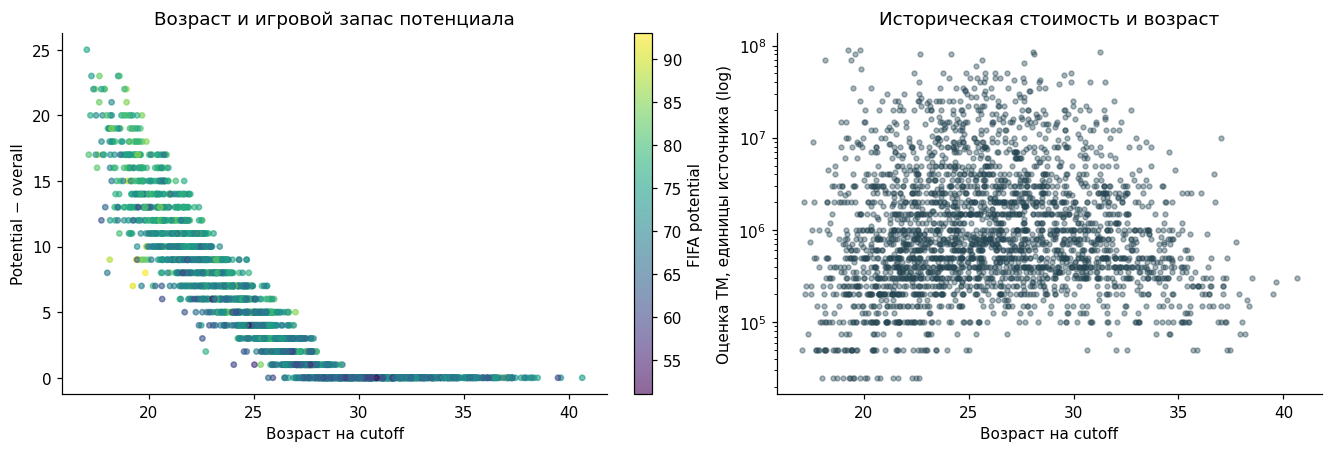

In [5]:
ECONOMIC = ["tm_market_value", "target_log1p_tm_value", "age_at_cutoff", "potential", "potential_gap"]
PERFORMANCE = ["goals_21_22", "assists_21_22", "minutes_21_22", "goals_per90", "assists_per90", "goals_per90_450", "assists_per90_450"]
display(enriched[ECONOMIC].describe().T.round(2))
display(pd.DataFrame({"group": ["Technical / playing", "Performance", "Economic"],
                      "columns": [", ".join(CORE), ", ".join(PERFORMANCE), ", ".join(ECONOMIC)],
                      "similarity_input": [True, False, False]}))
fig, axes = plt.subplots(1, 2, figsize=(12, 4), layout="constrained")
scatter = axes[0].scatter(enriched.age_at_cutoff, enriched.potential_gap, c=enriched.potential, cmap="viridis", s=12, alpha=.6)
axes[0].set(title="Возраст и игровой запас потенциала", xlabel="Возраст на cutoff", ylabel="Potential − overall")
fig.colorbar(scatter, ax=axes[0], label="FIFA potential")
axes[1].scatter(enriched.age_at_cutoff, enriched.tm_market_value, s=10, alpha=.4, color="#264653")
axes[1].set_yscale("log")
axes[1].set(title="Историческая стоимость и возраст", xlabel="Возраст на cutoff", ylabel="Оценка TM, единицы источника (log)")
show(fig, "03_economic_context")


### 4. Разделение до fit и стандартизация игровых признаков

Формула: `z = (x − mean_train) / std_train`, где стандартное отклонение — популяционное (`ddof=0`), как у StandardScaler. Даже при общей шкале FIFA 1–99 разбросы атрибутов различаются.

Фиксируем split 80/20 с seed 42 по идентификатору игрока. Fit scaler **только на train**, затем transform всего набора с сохранением роли train/test. Среднее и std проверяются на train; у test они не обязаны быть 0 и 1. Если позднее используется cross-validation, scaler требуется заново fit внутри каждого fold.

Две матрицы: обычные z-score и вариант с равными весами семи блоков v1. Вес признака после стандартизации — `sqrt(1 / (7 * число_признаков_блока))`. Это фиксированная содержательная настройка; её преимущество не объявляется доказанным. Для cosine similarity или расстояний нужно заранее выбрать одну матрицу.


In [6]:
splitter = GroupShuffleSplit(n_splits=1, test_size=.2, random_state=SEED)
train_idx, test_idx = next(splitter.split(enriched, groups=enriched.fifa_id))
train_mask = pd.Series(False, index=enriched.index)
train_mask.iloc[train_idx] = True
assert set(enriched.iloc[train_idx].fifa_id).isdisjoint(set(enriched.iloc[test_idx].fifa_id))
enriched["split"] = np.where(train_mask, "train", "test")
X = enriched[CORE].astype(float)
scaler = StandardScaler()
scaler.fit(X.loc[train_mask])
Z = pd.DataFrame(scaler.transform(X), columns=CORE, index=enriched.index)
assert np.allclose(Z.loc[train_mask].mean(), 0, atol=1e-12)
assert np.allclose(Z.loc[train_mask].std(ddof=0), 1, atol=1e-12)
assert np.allclose(scaler.mean_, X.loc[train_mask].mean())

group_of = {feature: group for group, features in CONTRACT["similarity_feature_groups"].items() for feature in features}
weights = np.array([np.sqrt(1 / (len(CONTRACT["similarity_feature_groups"]) * len(CONTRACT["similarity_feature_groups"][group_of[f]]))) for f in CORE])
Z_weighted = Z.mul(weights, axis=1)
assert set(group_of) == set(CORE)
assert np.isfinite(Z_weighted.to_numpy()).all()
assert (np.linalg.norm(Z_weighted.to_numpy(), axis=1) > 0).all()
display(enriched.split.value_counts().to_frame("players"))
display(pd.DataFrame({"feature": CORE, "train_mean_raw": scaler.mean_, "train_std_raw": scaler.scale_,
                      "train_mean_z": Z.loc[train_mask].mean().values, "test_mean_z": Z.loc[~train_mask].mean().values,
                      "block": [group_of[f] for f in CORE], "weight": weights}).round(4))


,players
split,
train,2308
test,578


,feature,train_mean_raw,train_std_raw,train_mean_z,test_mean_z,block,weight
0,attacking_short_passing,69.9515,6.4064,-0.0,0.0381,passing,0.2182
1,skill_long_passing,66.9918,7.1258,0.0,0.0157,passing,0.2182
2,mentality_vision,65.7223,8.0434,0.0,0.0522,passing,0.2182
3,skill_ball_control,68.7348,6.9040,-0.0,0.0467,ball_control,0.2673
4,skill_dribbling,66.5412,7.5492,0.0,0.0349,ball_control,0.2673
5,movement_agility,69.5867,9.5230,0.0,0.0294,mobility,0.1890
6,movement_balance,70.7626,10.1849,0.0,0.0580,mobility,0.1890
7,movement_reactions,65.2266,7.5831,-0.0,0.0427,decisions,0.2673
8,mentality_composure,64.9289,9.1187,0.0,0.0662,decisions,0.2673
9,power_stamina,71.8180,11.1435,0.0,0.0168,physical,0.2182


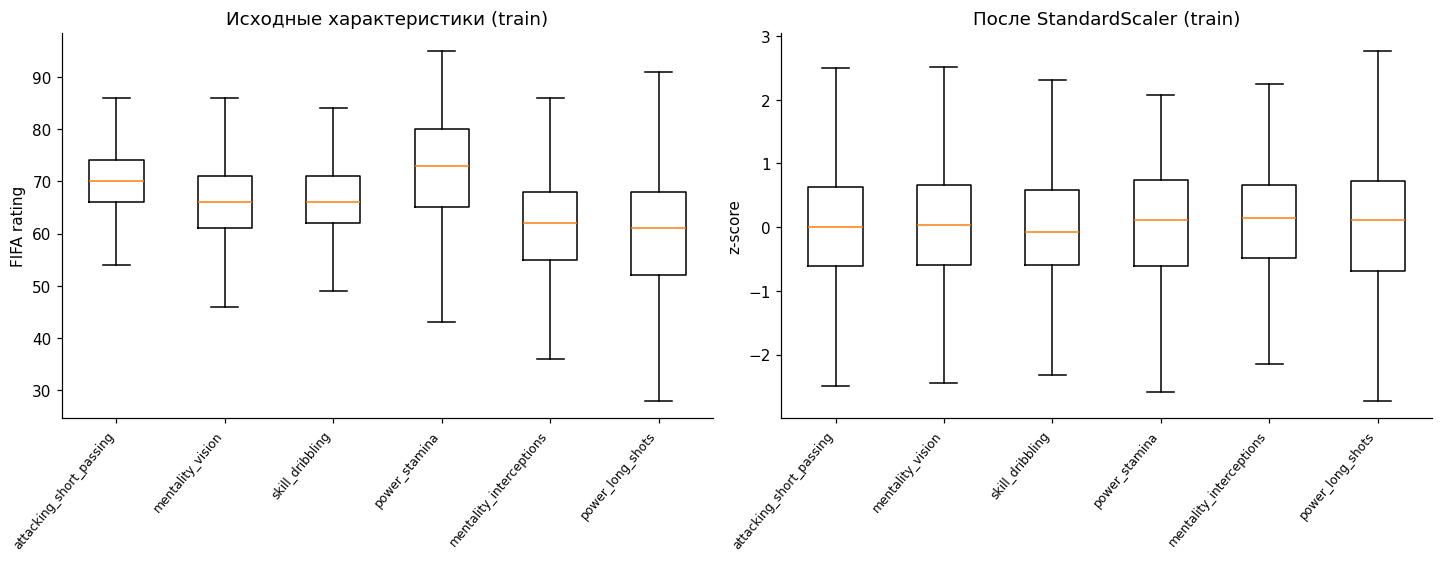

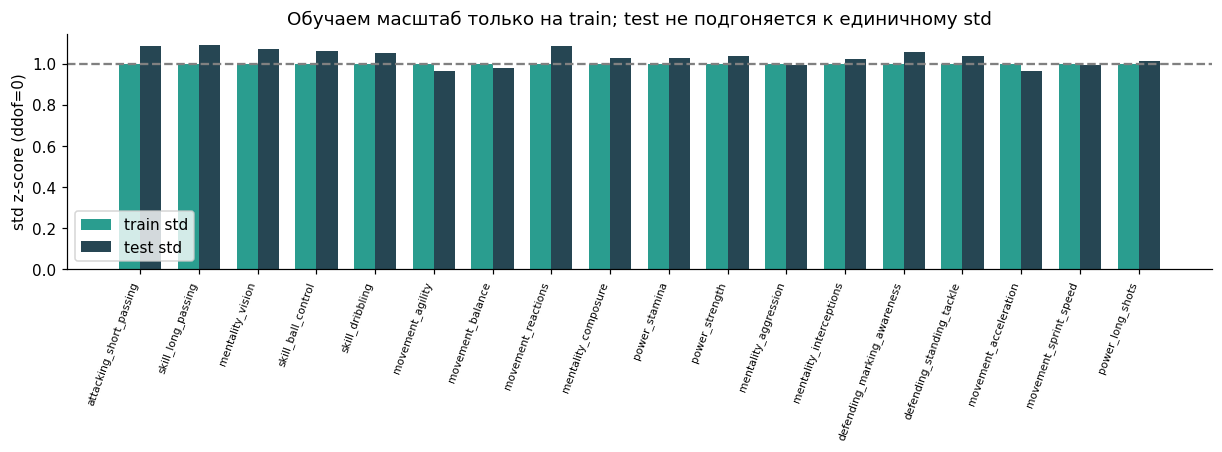

In [7]:
sample_features = ["attacking_short_passing", "mentality_vision", "skill_dribbling", "power_stamina", "mentality_interceptions", "power_long_shots"]
fig, axes = plt.subplots(1, 2, figsize=(13, 5), layout="constrained")
for ax, matrix, title in [(axes[0], X, "Исходные характеристики (train)"), (axes[1], Z, "После StandardScaler (train)")]:
    ax.boxplot([matrix.loc[train_mask, f].values for f in sample_features], showfliers=False)
    ax.set_xticks(range(1, len(sample_features)+1), sample_features, rotation=50, ha="right", fontsize=8)
    ax.set_title(title)
    ax.set_ylabel("FIFA rating" if ax is axes[0] else "z-score")
show(fig, "04_standardization")

fig, ax = plt.subplots(figsize=(11, 4), layout="constrained")
positions = np.arange(len(CORE))
ax.bar(positions-.18, Z.loc[train_mask].std(ddof=0), width=.36, color="#2a9d8f", label="train std")
ax.bar(positions+.18, Z.loc[~train_mask].std(ddof=0), width=.36, color="#264653", label="test std")
ax.set_xticks(positions, CORE, rotation=70, ha="right", fontsize=7)
ax.axhline(1, color="grey", linestyle="--")
ax.set(title="Обучаем масштаб только на train; test не подгоняется к единичному std", ylabel="std z-score (ddof=0)")
ax.legend()
show(fig, "05_train_test_scaling")


### 5. Матрица для оценки стоимости: отдельный allowlist

Сохраняем 27 исходных входов v1. У числовых полей пропуски заполняются медианой train и выполняется стандартизация; категории кодируются one-hot, неизвестные категории test игнорируются. Fit только на train. Семь неизвестных league_level не заполнялись глобальной медианой в Step 2.

Цена — `y`, а не вход X_value. Potential и performance пока остаются отдельными слоями анализа и не меняют зафиксированный v1. Количество кодированных колонок может быть больше 27.


In [8]:
numeric_value = CORE + CONTRACT["valuation_additional_numeric_features"]
categorical_value = CONTRACT["valuation_additional_categorical_features"]
value_transformer = ColumnTransformer([
    ("numeric", Pipeline([("imputer", SimpleImputer(strategy="median")), ("scaler", StandardScaler())]), numeric_value),
    ("categorical", OneHotEncoder(handle_unknown="ignore", sparse_output=False), categorical_value),
], remainder="drop")
value_transformer.fit(enriched.loc[train_mask, VALUE_FEATURES])
V = pd.DataFrame(value_transformer.transform(enriched[VALUE_FEATURES]), columns=value_transformer.get_feature_names_out(), index=enriched.index)
assert np.isfinite(V.to_numpy()).all()
assert set(value_transformer.feature_names_in_) == set(VALUE_FEATURES)
imputer = value_transformer.named_transformers_["numeric"].named_steps["imputer"]
assert np.allclose(imputer.statistics_, enriched.loc[train_mask, numeric_value].median().values)
print("Similarity standardized:", Z.shape, "; similarity weighted:", Z_weighted.shape, "; valuation encoded:", V.shape)
display(V.head())


Similarity standardized: (2886, 18) ; similarity weighted: (2886, 18) ; valuation encoded: (2886, 80)


,numeric__attacking_short_passing,numeric__skill_long_passing,numeric__mentality_vision,numeric__skill_ball_control,numeric__skill_dribbling,numeric__movement_agility,numeric__movement_balance,numeric__movement_reactions,numeric__mentality_composure,numeric__power_stamina,numeric__power_strength,numeric__mentality_aggression,numeric__mentality_interceptions,numeric__defending_marking_awareness,numeric__defending_standing_tackle,numeric__movement_acceleration,numeric__movement_sprint_speed,...,categorical__league_id_39,categorical__league_id_4,categorical__league_id_41,categorical__league_id_50,categorical__league_id_53,categorical__league_id_54,categorical__league_id_56,categorical__league_id_60,categorical__league_id_61,categorical__league_id_63,categorical__league_id_64,categorical__league_id_65,categorical__league_id_66,categorical__league_id_68,categorical__league_id_80,categorical__league_id_83,categorical__league_id_UNKNOWN
0,1.568516,0.843168,0.531831,0.617781,0.325707,-0.796665,-1.547641,1.684452,1.214109,-0.970793,0.844537,0.231999,1.107611,1.278826,1.171573,-1.241051,-1.613927,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0
1,-0.460708,-0.700522,0.034529,-0.830653,-0.866467,-4.051935,-1.744010,-0.557370,1.214109,0.285546,1.200018,0.909467,0.402844,0.645586,0.409832,-3.717741,-3.136301,...,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2,1.724610,1.685181,1.402110,1.631684,1.252953,-0.586647,0.121497,2.475683,1.762435,0.375284,0.489056,1.840986,1.548090,1.640678,1.742878,-1.348733,-1.410944,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
3,0.319763,0.281826,0.904808,0.038407,0.458171,-0.901674,-0.074872,0.893221,0.446453,-0.163147,-0.133036,0.486050,0.931419,1.007438,0.885920,-2.748602,-2.019894,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
4,0.475857,0.702832,1.153459,0.183251,0.193243,-0.481639,0.219682,1.025092,0.336788,-0.163147,0.755666,0.655417,1.195707,1.278826,1.171573,-0.379594,-2.019894,...,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


### 6. Проверки формул, временных границ и разделения ролей

Контрольные примеры проверяют 180 минут, нулевые/отрицательные/пропущенные минуты и неизвестные голы. Отдельно проверяется инвариантность игрового вектора к изменению стоимости, возраста и потенциала. Статистика scaler должна совпадать с train и оставаться неизменной при transform изменённого test.


In [9]:
fixture_n = pd.Series([2, 1, 3, 0, 2, 2, np.nan, -1])
fixture_m = pd.Series([180, 180, 180, 90, 0, -10, 90, 90])
rates = per90(fixture_n, fixture_m)
assert np.allclose(rates.iloc[:4], [1., .5, 1.5, 0.])  # 3 goals / 180 includes every goal
assert rates.iloc[4:].isna().all()
assert pd.isna(per90(pd.Series([1]), pd.Series([np.nan])).iloc[0])
assert pd.isna(complete_sum(pd.Series([90., np.nan])))
assert complete_sum(pd.Series([90., 90.])) == 180

changed_economics = enriched.copy()
changed_economics["tm_market_value"] *= 1_000_000
changed_economics["age_at_cutoff"] += 50
changed_economics["potential"] = 1
assert np.allclose(scaler.transform(changed_economics[CORE]), Z.to_numpy())
old_mean, old_scale = scaler.mean_.copy(), scaler.scale_.copy()
_ = scaler.transform(X.loc[~train_mask] + 1000)
assert np.array_equal(scaler.mean_, old_mean) and np.array_equal(scaler.scale_, old_scale)

checks = {
    "unique_player_rows": enriched.fifa_id.is_unique and enriched.tm_id.is_unique,
    "fixed_fifa_and_potential_date": enriched.fifa_update_date.eq(CUTOFF).all() and enriched.potential_source_date.eq(CUTOFF).all(),
    "no_future_market_value": enriched.market_value_date.le(CUTOFF).all(),
    "only_selected_previous_season": enriched.loc[enriched.has_performance_record, "performance_season"].eq(PERFORMANCE_SEASON).all(),
    "no_row_multiplication": len(enriched) == len(players),
    "all_core_complete": X.notna().all().all(),
    "economic_and_performance_excluded_from_similarity": not set(CORE) & set(ECONOMIC + PERFORMANCE),
    "price_excluded_from_value_inputs": not set(VALUE_FEATURES) & {"tm_market_value", "target_log1p_tm_value", "value_eur", "wage_eur", "release_clause_eur"},
    "disjoint_train_test_players": set(enriched.loc[train_mask, "fifa_id"]).isdisjoint(set(enriched.loc[~train_mask, "fifa_id"])),
    "scaler_fitted_train_only": int(scaler.n_samples_seen_) == int(train_mask.sum()),
    "train_mean_zero_std_one": np.allclose(Z.loc[train_mask].mean(), 0, atol=1e-12) and np.allclose(Z.loc[train_mask].std(ddof=0), 1, atol=1e-12),
    "finite_style_and_value_matrices": np.isfinite(Z_weighted).all().all() and np.isfinite(V).all().all(),
    "per90_missing_when_invalid_minutes": enriched.loc[enriched.minutes_21_22.isna() | enriched.minutes_21_22.le(0), ["goals_per90", "assists_per90"]].isna().all().all(),
    "reliable_goals_minimum_450": enriched.loc[enriched.goals_per90_450.notna(), "minutes_21_22"].ge(MIN_RELIABLE_MINUTES).all(),
    "reliable_assists_minimum_450": enriched.loc[enriched.assists_per90_450.notna(), "minutes_21_22"].ge(MIN_RELIABLE_MINUTES).all(),
    "immutable_core_contract": list(Z.columns) == CORE and len(CORE) == 18,
}
assert all(checks.values()), {k:v for k,v in checks.items() if not v}
display(pd.DataFrame({"check": checks.keys(), "passed": checks.values()}))


,check,passed
0,unique_player_rows,True
1,fixed_fifa_and_potential_date,True
2,no_future_market_value,True
3,only_selected_previous_season,True
4,no_row_multiplication,True
5,all_core_complete,True
6,economic_and_performance_excluded_from_similarity,True
7,price_excluded_from_value_inputs,True
8,disjoint_train_test_players,True
9,scaler_fitted_train_only,True


### 7. Экспорт признаков и параметров преобразования

В `data/processed/features/` сохраняются объединённая таблица анализа, три матрицы, performance/economic-слои, split, JSON с параметрами fit, manifest и очередь конфликтов performance. Матрицы содержат `fifa_id` как ключ, **не как числовой вход**. Для модели удаляйте ID или используйте список matrix_columns manifest.

Пропуски performance сохраняются — это отсутствие измерений, не нулевая результативность. Их не следует автоматически включать в обучение и заполнять нулями. При последующих экспериментах требуется отдельная политика отсутствующих наблюдений и проверка временной доступности.


In [10]:
id_columns = ["fifa_id", "tm_id", "as_of_date", "split"]
outputs = {}
def export(frame, filename):
    path = OUT / filename
    frame.to_csv(path, index=False)
    outputs[filename] = {"rows": len(frame), "columns": len(frame.columns), "sha256": digest(path)}
    return path

export(enriched, f"moneyball_features_{CUTOFF}.csv")
export(pd.concat([enriched[["fifa_id"]], Z], axis=1), "X_similarity_standardized.csv")
export(pd.concat([enriched[["fifa_id"]], Z_weighted], axis=1), "X_similarity_weighted.csv")
export(pd.concat([enriched[["fifa_id"]], V], axis=1), "X_valuation_encoded.csv")
export(enriched[id_columns + PERFORMANCE + ["performance_season", "assumed_season_end", "has_performance_record", "minutes_known", "goals_per90_reliable", "assists_per90_reliable"]], "performance_features.csv")
export(enriched[id_columns + ECONOMIC + ["potential_source_date", "market_value_date", "market_value_age_days"]], "economic_features.csv")
export(enriched[["fifa_id", "tm_id", "split"]], "player_split.csv")
export(conflict_rows, "performance_conflicting_keys.csv")

value_numeric_scaler = value_transformer.named_transformers_["numeric"].named_steps["scaler"]
encoder = value_transformer.named_transformers_["categorical"]
transform_parameters = {
    "fit_split": "train", "seed": SEED, "n_train": int(train_mask.sum()), "n_test": int((~train_mask).sum()),
    "train_ids_sha256": hashlib.sha256("\n".join(sorted(enriched.loc[train_mask, "fifa_id"])).encode()).hexdigest(),
    "similarity": {"features": CORE, "mean": scaler.mean_.tolist(), "scale": scaler.scale_.tolist(), "variance": scaler.var_.tolist(), "weights": weights.tolist()},
    "valuation": {"numeric_features": numeric_value, "imputer_medians": imputer.statistics_.tolist(),
                  "mean": value_numeric_scaler.mean_.tolist(), "scale": value_numeric_scaler.scale_.tolist(),
                  "categorical_features": categorical_value, "categories": [a.tolist() for a in encoder.categories_],
                  "encoded_columns": V.columns.tolist(), "handle_unknown": "ignore"},
}
(OUT / "transform_parameters.json").write_text(json.dumps(transform_parameters, ensure_ascii=False, indent=2), encoding="utf-8")
saved = json.loads((OUT / "transform_parameters.json").read_text(encoding="utf-8"))
reconstructed = (X.to_numpy() - np.array(saved["similarity"]["mean"])) / np.array(saved["similarity"]["scale"])
assert np.allclose(reconstructed, Z.to_numpy())
for name, matrix in [("X_similarity_standardized.csv", Z), ("X_similarity_weighted.csv", Z_weighted), ("X_valuation_encoded.csv", V)]:
    reloaded = pd.read_csv(OUT / name, dtype={"fifa_id": str})
    assert reloaded.fifa_id.tolist() == enriched.fifa_id.tolist()
    assert np.allclose(reloaded.drop(columns="fifa_id").to_numpy(), matrix.to_numpy())

manifest = {
    "cutoff": CUTOFF, "rows": len(enriched), "input_sha256": input_manifest["sha256"], "source_sha256": source_hashes,
    "groups": {"technical_playing": CORE, "performance": PERFORMANCE, "economic": ECONOMIC},
    "matrix_columns": {"X_similarity_standardized.csv": CORE, "X_similarity_weighted.csv": CORE, "X_valuation_encoded.csv": V.columns.tolist()},
    "economic_roles": {"tm_market_value": "target_and_budget_only", "age_at_cutoff": "valuation_v1_and_analysis", "potential": "analysis_only", "potential_gap": "analysis_only"},
    "performance_policy": {"season": PERFORMANCE_SEASON, "assumed_end": ASSUMED_SEASON_END, "publication_time": "unverified_retrospective_only",
                           "goals_include_penalties": True, "minimum_reliable_minutes": MIN_RELIABLE_MINUTES, "core_model_input": False},
    "performance_coverage": coverage.to_dict("records"), "train_rows": int(train_mask.sum()), "test_rows": int((~train_mask).sum()),
    "feature_contract": CONTRACT["version"], "outputs": outputs, "validation": {k:bool(v) for k,v in checks.items()},
    "matrix_roundtrip": "passed", "parameter_roundtrip": "passed", "sklearn_version": sklearn.__version__,
}
(OUT / "feature_manifest.json").write_text(json.dumps(manifest, ensure_ascii=False, indent=2), encoding="utf-8")
display(pd.DataFrame(outputs).T)
display(Markdown(f"**Готово:** {len(enriched):,} игроков; 18 игровых входов сходства; {V.shape[1]} кодированных входов оценки стоимости. "
                 f"Train/test: {int(train_mask.sum())}/{int((~train_mask).sum())}. "
                 "Goals/90 и Assists/90 рассчитаны отдельно с явным покрытием. Цена, возраст и potential не попали в вектор сходства."))


,rows,columns,sha256
moneyball_features_2022-09-26.csv,2886,65,87a552730bd4f3832a8ba175aa508feade3fad4665697d...
X_similarity_standardized.csv,2886,19,4011b7e7fc8f696ac2468dc869b0742be724dce60f70b9...
X_similarity_weighted.csv,2886,19,64a4702b8b2cfdccbfadd40dc92e51f57e649c6affa3bb...
X_valuation_encoded.csv,2886,81,af4a525bcd52caa1232e8a4e2b6a7404e74c5e865db3b3...
performance_features.csv,2886,17,a5d7250cdb4fd5a52873b37fefe8def2f74cc0c2bcc1cb...
economic_features.csv,2886,12,fea9630fdf062574243db381eaa1edc35ea7602649bcb8...
player_split.csv,2886,3,d777408f4f8d913bfa95fb958ae9991ada241607323fa2...
performance_conflicting_keys.csv,0,7,616d206afc9e82d35ab94f5b26dc0497d31cf054f0585a...


**Готово:** 2,886 игроков; 18 игровых входов сходства; 80 кодированных входов оценки стоимости. Train/test: 2308/578. Goals/90 и Assists/90 рассчитаны отдельно с явным покрытием. Цена, возраст и potential не попали в вектор сходства.